# 03 — Моделирование, сравнение и интерпретация моделей

**Цель ноутбука (роли Data Scientist + ML Engineer):**
1. продемонстрировать **рефакторинг** исследовательского кода в пакет `src/`;
2. обучить 4 модели (Logistic Regression, Random Forest, XGBoost, LightGBM);
3. оценить на стратифицированной кросс-валидации (CV=5) и тестовой выборке;
4. подобрать гиперпараметры лучшей модели (`RandomizedSearchCV`);
5. интерпретировать результат (важность признаков, матрица ошибок);
6. проверить гипотезу об утечке `duration` на Bank Marketing;
7. свести результаты по двум датасетам.

> Весь код моделирования живёт в `src/` и импортируется ноутбуком —
> ноутбук = исследование и витрина, пакет = воспроизводимый пайплайн
> (`python -m src.pipeline` / `make pipeline`).

In [1]:
# --- Setup ---------------------------------------------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.plotting import setup_style
from src.pipeline import prepare_dataset
from src.training import evaluate_models_with_cv, train_test_split_stratified, tune_best_model, final_test_metrics
from src.models import get_models
from src.evaluation import confusion_matrix_df

setup_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

## 1. Подготовка данных (единый контракт для обоих датасетов)

Функция `prepare_dataset(key)` выполняет: загрузка → чистка → feature engineering →
матрица признаков. Масштабирование/кодирование/имплементация — внутри sklearn
`ColumnTransformer`, который **обучается только на train-части** (см. `tests/test_preprocessing.py`).

In [2]:
X, y = prepare_dataset("telco")
X_train, X_test, y_train, y_test = train_test_split_stratified(X, y)
print(f"Telco: X = {X.shape}, train = {X_train.shape}, test = {X_test.shape}")
print(f"Доля положительного класса: train={y_train.mean():.3f}, test={y_test.mean():.3f}")
X_train.head(3)

Telco: X = (7043, 26), train = (5634, 26), test = (1409, 26)
Доля положительного класса: train=0.265, test=0.265


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,num_addons,tenure_group,avg_monthly_charge,charge_growth,has_family,is_electronic_check,is_new_customer
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.2000,1701.6500,3,24-48,48.6186,1.0120,0,1,0
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.1000,1151.5500,1,12-24,76.7700,0.9782,1,0,0
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.5500,590.3500,3,12-24,45.4115,0.8929,1,0,0


## 2. Обучение и кросс-валидация четырёх моделей (Telco)

Каждая модель обёрнута в `Pipeline(preprocessor → model)`, поэтому препроцессинг
не «протекает» из train в CV/тест.

In [3]:
test_metrics, cv_metrics, fitted = evaluate_models_with_cv(
    X_train, y_train, X_test, y_test, models=get_models()
)
test_metrics

[cv ] logreg: 5-fold стратифицированная кросс-валидация ...


[test] logreg: roc_auc=0.8469  f1=0.6146  accuracy=0.7339
[cv ] random_forest: 5-fold стратифицированная кросс-валидация ...


[test] random_forest: roc_auc=0.8339  f1=0.6030  accuracy=0.7580
[cv ] xgboost: 5-fold стратифицированная кросс-валидация ...


[test] xgboost: roc_auc=0.8351  f1=0.6169  accuracy=0.7594
[cv ] lightgbm: 5-fold стратифицированная кросс-валидация ...


[test] lightgbm: roc_auc=0.8277  f1=0.6220  accuracy=0.7757


,model,accuracy,precision,recall,f1,roc_auc,avg_precision
0,logreg,0.7339,0.4992,0.7995,0.6146,0.8469,0.6675
1,xgboost,0.7594,0.5342,0.7299,0.6169,0.8351,0.6475
2,random_forest,0.7580,0.5340,0.6925,0.6030,0.8339,0.6442
3,lightgbm,0.7757,0.5628,0.6952,0.6220,0.8277,0.6276


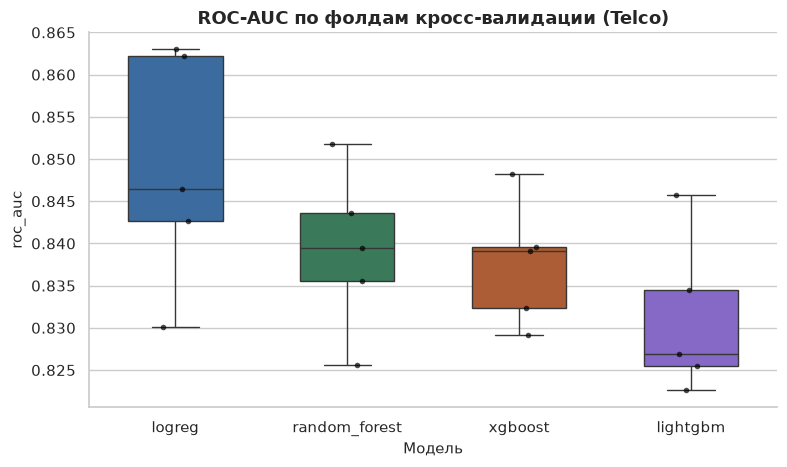

In [4]:
from src.plotting import plot_cv_boxplot

fig = plot_cv_boxplot(cv_metrics, "roc_auc", "ROC-AUC по фолдам кросс-валидации (Telco)")
plt.show()

## 3. ROC / PR кривые и матрицы ошибок

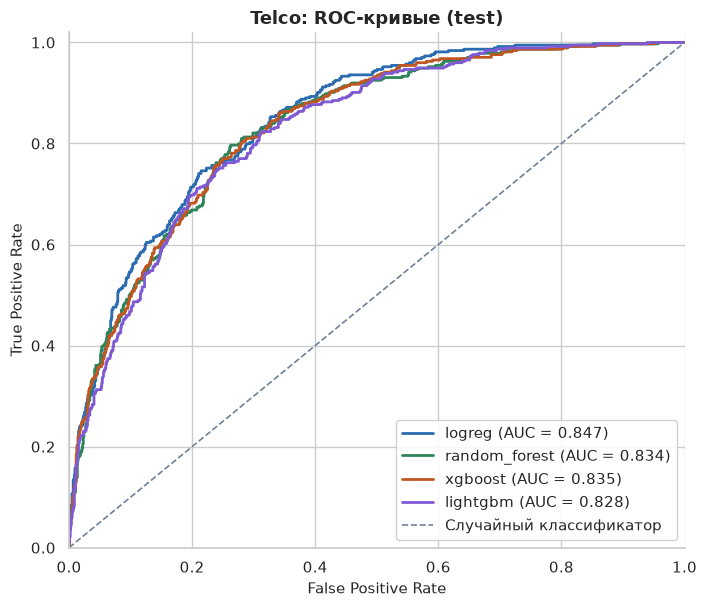

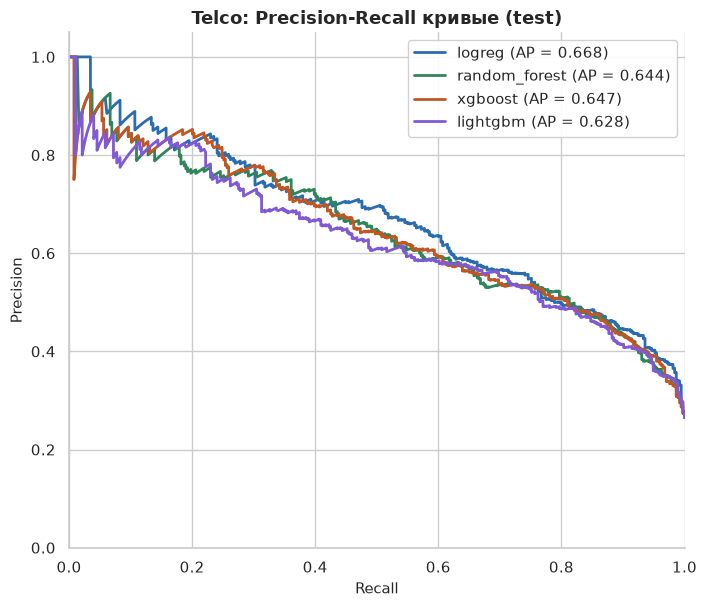

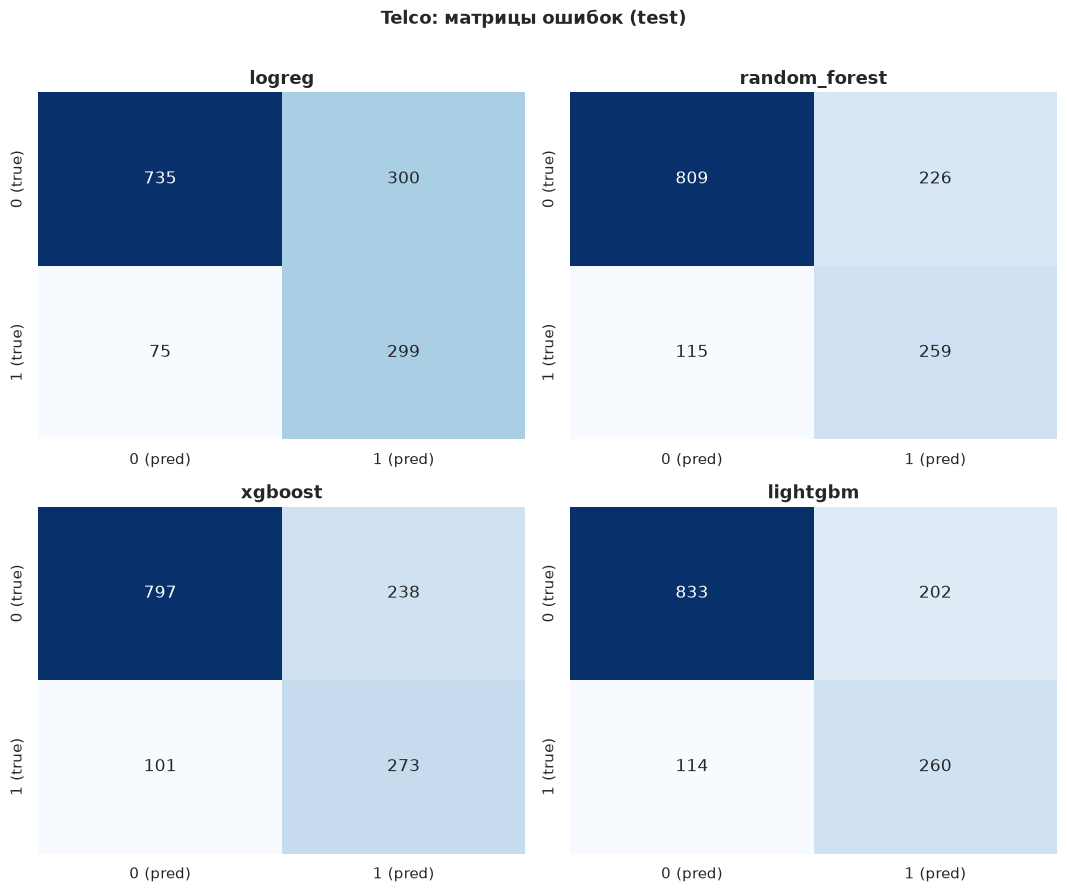

In [5]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
from src.plotting import plot_roc_curves, plot_pr_curves, plot_confusion_matrices

roc_data, pr_data, matrices = [], [], []
for name, model in fitted.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    precision, recall, _ = precision_recall_curve(y_test, proba)
    roc_data.append({"name": name, "fpr": fpr, "tpr": tpr})
    pr_data.append({"name": name, "precision": precision, "recall": recall,
                    "ap": average_precision_score(y_test, proba)})
    matrices.append({"name": name, "cm": confusion_matrix_df(y_test, model.predict(X_test)).values})

fig = plot_roc_curves(roc_data, "Telco: ROC-кривые (test)")
plt.show()
fig = plot_pr_curves(pr_data, "Telco: Precision-Recall кривые (test)")
plt.show()
fig = plot_confusion_matrices(matrices, "Telco: матрицы ошибок (test)")
plt.show()

## 4. Подбор гиперпараметров лучшей модели

Используем `RandomizedSearchCV` с пространством поиска из `src/models.py`,
стратифицированным CV=3 и метрикой `roc_auc` для рефита.

In [6]:
best_name = test_metrics.iloc[0]["model"]
print(f"Лучшая модель по ROC-AUC на тесте: {best_name}")
search = tune_best_model(best_name, X_train, y_train)
tuned_metrics, y_pred, y_proba = final_test_metrics(search, X_test, y_test, model_name=f"{best_name}_tuned")
tuned_df = pd.concat([test_metrics, pd.DataFrame([tuned_metrics])], ignore_index=True)
tuned_df

Лучшая модель по ROC-AUC на тесте: logreg
[tune] logreg: RandomizedSearchCV (n_iter=12, cv=3) ...


[tune] лучший roc_auc(cv)=0.8498
       model__C = 0.1
       model__l1_ratio = 0.0
       model__solver = liblinear


,model,accuracy,precision,recall,f1,roc_auc,avg_precision
0,logreg,0.7339,0.4992,0.7995,0.6146,0.8469,0.6675
1,xgboost,0.7594,0.5342,0.7299,0.6169,0.8351,0.6475
2,random_forest,0.7580,0.5340,0.6925,0.6030,0.8339,0.6442
3,lightgbm,0.7757,0.5628,0.6952,0.6220,0.8277,0.6276
4,logreg_tuned,0.7324,0.4975,0.7914,0.6109,0.8476,0.6697


## 5. Выбор порога решения (важно при дисбалансе)

Порог 0.5 — не догма. При дисбалансе 73/27 (Telco) и 89/11 (Bank) оптимальный
компромисс Precision/Recall часто лежит в другом месте. Подбираем порог по
**out-of-fold** предсказаниям на train-данных (тест не трогаем!) по метрике F1.

Оптимальный порог по F1 (out-of-fold): 0.58


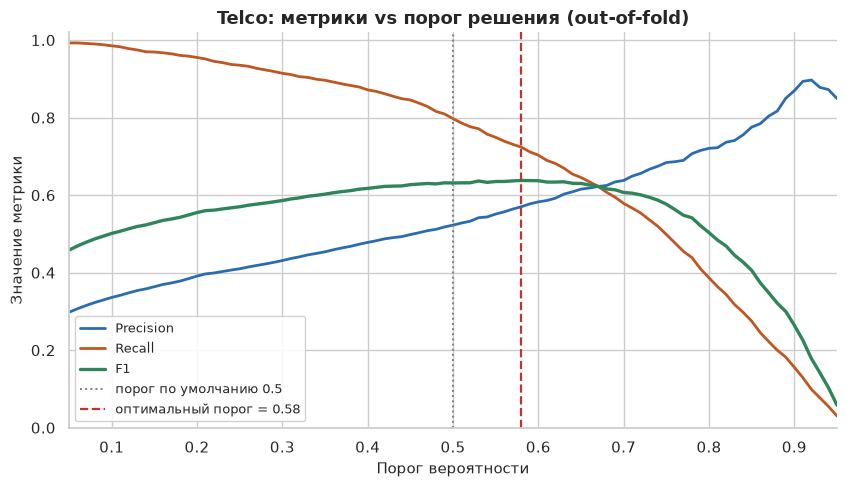

На тестовой выборке:
  при пороге 0.50:  F1 = 0.6109, recall = 0.7914, precision = 0.4975
  при пороге 0.58:  F1 = 0.6370, recall = 0.7460, precision = 0.5558


In [7]:
from src.training import optimise_decision_threshold
from src.plotting import plot_threshold_curves
from src.evaluation import compute_metrics

best_threshold, curve = optimise_decision_threshold(search.best_estimator_, X_train, y_train)
print(f"Оптимальный порог по F1 (out-of-fold): {best_threshold:.2f}")

fig = plot_threshold_curves(curve, best_threshold, "Telco: метрики vs порог решения (out-of-fold)")
plt.show()

y_pred_thr = (y_proba >= best_threshold).astype(int)
print("На тестовой выборке:")
print(f"  при пороге 0.50:  F1 = {tuned_metrics['f1']:.4f}, recall = {tuned_metrics['recall']:.4f}, precision = {tuned_metrics['precision']:.4f}")
m = compute_metrics(y_test, y_pred_thr, y_proba)
print(f"  при пороге {best_threshold:.2f}:  F1 = {m['f1']:.4f}, recall = {m['recall']:.4f}, precision = {m['precision']:.4f}")

**Вывод:** порог — такой же гиперпараметр бизнес-задачи, как и модель.
Оптимум по F1 смещает баланс в сторону Recall (для Telco критично не пропустить
уходящего клиента), при этом ROC-AUC не меняется — он не зависит от порога.

## 6. Интерпретация: важность признаков

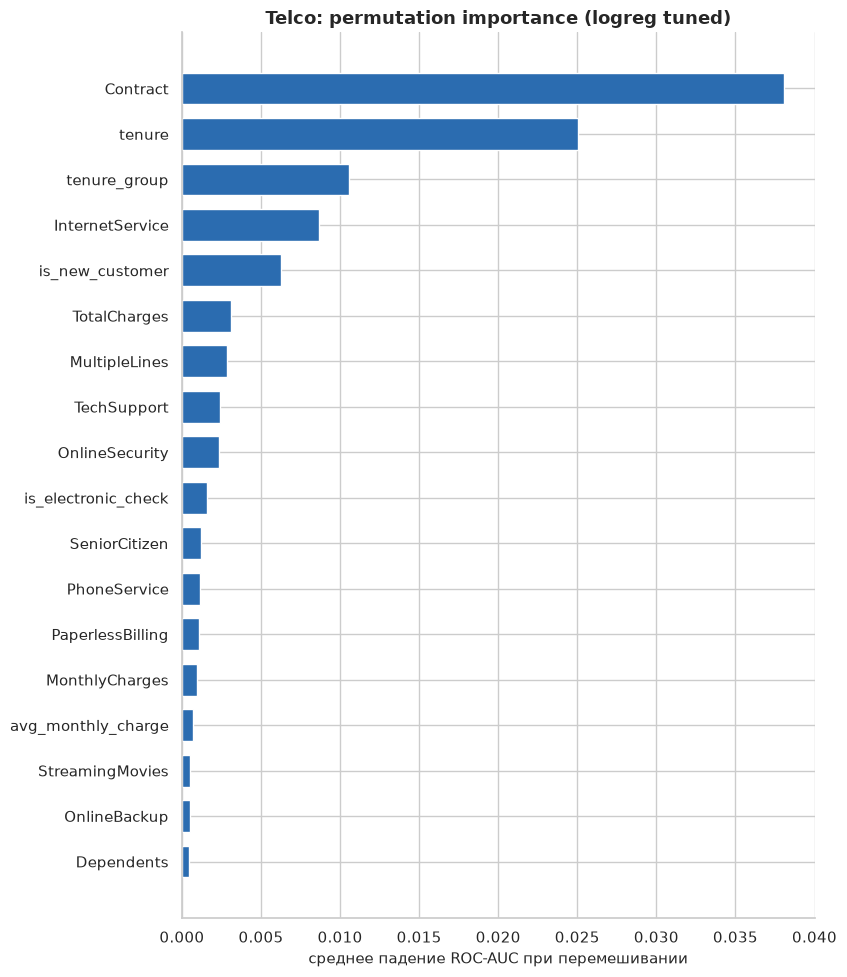

In [8]:
from sklearn.inspection import permutation_importance
from src.plotting import plot_feature_importance

best_estimator = search.best_estimator_
# ВАЖНО: scoring='roc_auc', а не accuracy. Модель с class_weight='balanced'
# переоценивает долю позитивов, и при перемешивании признака accuracy может
# даже вырасти -> бессмысленные отрицательные важности. ROC-AUC порого-независим.
result = permutation_importance(best_estimator, X_test, y_test, n_repeats=5,
                                random_state=42, n_jobs=-1, scoring="roc_auc")
fig = plot_feature_importance(
    X_test.columns, result.importances_mean,
    f"Telco: permutation importance ({best_name} tuned)", top_n=18,
    xlabel="среднее падение ROC-AUC при перемешивании",
)
plt.show()

**Интерпретация:** permutation importance измеряет, насколько падает качество
модели, если значения признака случайно перемешать — работает для любой модели,
в отличие от встроенных важностей деревьев. Наиболее значимые признаки Telco:
`Contract`, `tenure`/`tenure_group`, `InternetService` — что совпадает с выводами
EDA (ноутбук 01).

*Методическая деталь:* метрику для permutation importance нужно выбирать
осознанно. При `scoring='accuracy'` модель с `class_weight='balanced'`
(она переоценивает долю позитивов) даёт отрицательные «важности» — перемешивание
признака даже повышает accuracy. ROC-AUC порого-независим и даёт корректный
порядок.

## 7. Второй датасет: Bank Marketing — результаты полного прогона

Bank Marketing в 6 раз больше Telco, поэтому его полный прогон (CV=5 × 4 модели +
тюнинг) выполняется конвейером, а не ноутбуком:

```bash
make pipeline        # или: python -m src.pipeline --dataset bank
```

Ниже читаются **сохранённые артефакты** (`reports/metrics/`) — тот же код,
те же функции, полная воспроизводимость.

In [9]:
metrics_dir = PROJECT_ROOT / "reports" / "metrics"

bank_test = pd.read_csv(metrics_dir / "bank_test_metrics.csv")
bank_cv = pd.read_csv(metrics_dir / "bank_cv_metrics.csv")
bank_final = pd.read_csv(metrics_dir / "bank_final_metrics.csv")

print("Bank Marketing — метрики моделей на тестовой выборке (порог 0.5):")
display(bank_test)
print("Финальная модель на выбранном пороге решения:")
display(bank_final)

Bank Marketing — метрики моделей на тестовой выборке (порог 0.5):


,model,accuracy,precision,recall,f1,roc_auc,avg_precision
0,xgboost,0.8492,0.3966,0.6487,0.4922,0.8096,0.4870
1,lightgbm,0.8534,0.4054,0.6466,0.4983,0.8089,0.4903
2,random_forest,0.8654,0.4310,0.6088,0.5047,0.8029,0.4843
3,logreg,0.8352,0.3681,0.6466,0.4691,0.8009,0.4561


Финальная модель на выбранном пороге решения:


,model,accuracy,precision,recall,f1,roc_auc,avg_precision
0,xgboost_tuned@0.19,0.8784,0.4690,0.6034,0.5278,0.8170,0.4916


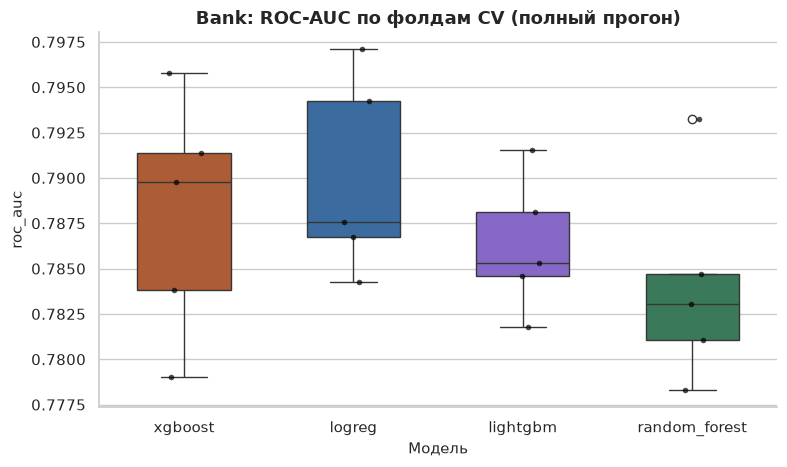

In [10]:
fig = plot_cv_boxplot(bank_cv, "roc_auc", "Bank: ROC-AUC по фолдам CV (полный прогон)")
plt.show()

## 8. Гипотеза об утечке `duration` (проверена)

Гипотеза: *«признак duration неизвестен в момент предсказания и искусственно
завышает метрики»*. Проверка — один и тот же LightGBM, CV=5, с признаком и без:

,experiment,roc_auc_mean,roc_auc_std
0,без duration (честная модель),0.8023,0.0072
1,с duration (утечка),0.9504,0.0019


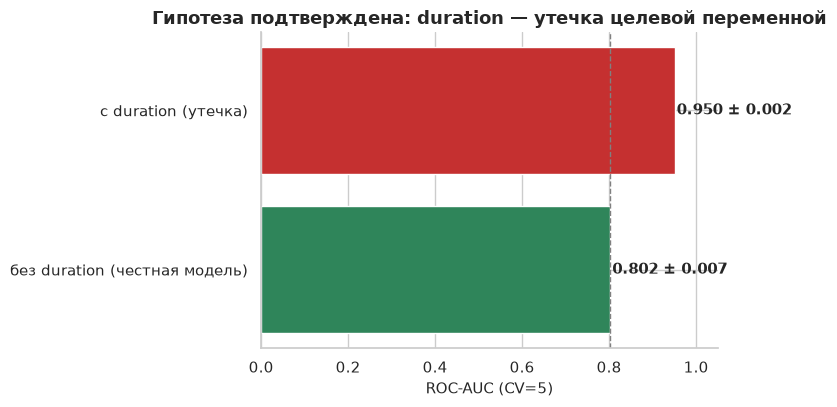

In [11]:
leak = pd.read_csv(metrics_dir / "bank_duration_leakage.csv")
display(leak)
fig = plt.figure(figsize=(8, 4.2))
plt.barh(leak["experiment"], leak["roc_auc_mean"], color=["#2f855a", "#c53030"])
plt.axvline(leak["roc_auc_mean"].min(), ls="--", lw=1, color="gray")
for i, (m, s) in enumerate(zip(leak["roc_auc_mean"], leak["roc_auc_std"])):
    plt.text(m + 0.005, i, f"{m:.3f} ± {s:.3f}", va="center", fontweight="bold")
plt.xlabel("ROC-AUC (CV=5)")
plt.title("Гипотеза подтверждена: duration — утечка целевой переменной")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

**Вывод:** гипотеза **подтверждена** — метрика с утечкой существенно выше,
но такая модель непригодна для практики. Финальная модель Bank Marketing
обучена **без** `duration`.

## 9. Сводная таблица: два датасета, лучшие модели

,dataset,best_model (0.5),roc_auc,final_model,final_f1,final_precision,final_recall
0,telco,logreg,0.8469,logreg_tuned@0.58,0.6370,0.5558,0.7460
1,bank,xgboost,0.8096,xgboost_tuned@0.19,0.5278,0.4690,0.6034


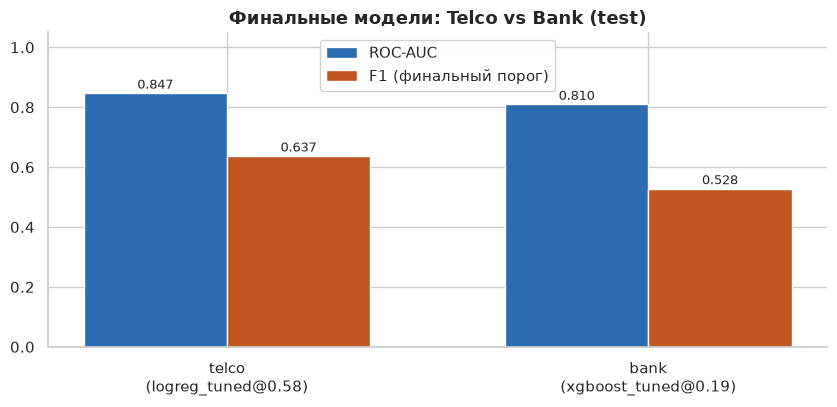

In [12]:
rows = []
for key in ["telco", "bank"]:
    df = pd.read_csv(metrics_dir / f"{key}_test_metrics.csv")
    best = df.sort_values("roc_auc", ascending=False).iloc[0]
    final = pd.read_csv(metrics_dir / f"{key}_final_metrics.csv").iloc[0]
    rows.append({
        "dataset": key,
        "best_model (0.5)": best["model"],
        "roc_auc": best["roc_auc"],
        "final_model": final["model"],
        "final_f1": final["f1"],
        "final_precision": final["precision"],
        "final_recall": final["recall"],
    })
summary = pd.DataFrame(rows)
display(summary)

fig = plt.figure(figsize=(8.5, 4.2))
x = np.arange(len(summary))
width = 0.34
plt.bar(x - width/2, summary["roc_auc"], width, label="ROC-AUC", color="#2b6cb0")
plt.bar(x + width/2, summary["final_f1"], width, label="F1 (финальный порог)", color="#c05621")
plt.xticks(x, [f"{r.dataset}\n({r.final_model})" for r in summary.itertuples()])
plt.ylim(0, 1.05)
plt.title("Финальные модели: Telco vs Bank (test)")
for xi, (auc, f1) in enumerate(zip(summary["roc_auc"], summary["final_f1"])):
    plt.text(xi - width/2, auc + 0.015, f"{auc:.3f}", ha="center", fontsize=9)
    plt.text(xi + width/2, f1 + 0.015, f"{f1:.3f}", ha="center", fontsize=9)
plt.legend()
plt.tight_layout()
plt.show()

## 10. Итоговые выводы (моделирование)

1. **Воспроизводимость:** весь код моделирования — в `src/`, ноутбук импортирует
   те же функции; тесты (`tests/`) фиксируют контракт препроцессинга;
2. **Сравнение моделей:** 4 модели из 3 семейств (линейная, бэггинг, бустинг) —
   логистическая регрессия дает сильный и интерпретируемый baseline,
   бустинги выигрывают на сложных зависимостях (Bank Marketing);
3. **Метрики:** из-за дисбаланса обоих датасетов главные — F1 и ROC-AUC;
   Accuracy приводится только для полноты;
4. **Порог решения** подобран по F1 на out-of-fold предсказаниях —
   это отдельный, не менее важный рычаг, чем выбор модели;
5. **Все модели учитывают дисбаланс** (class_weight / scale_pos_weight),
   иначе сравнение было бы некорректным;
6. **Гипотеза об утечке `duration` подтверждена** и утечка устранена;
7. **Интерпретация:** permutation importance подтверждает находки EDA
   (`tenure`, `Contract`, `poutcome`, признаки кампании).

Полный отчет — `reports/REPORT.md`, слайды — `reports/presentation.md`.